# 

In [66]:
# Выполнил: Осипов Никита Андреевич

In [82]:
import io
import zipfile
import urllib.request
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

import prophet as fp
from prophet.diagnostics import cross_validation

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, SeasonalNaive, MSTL, AutoTheta, HoltWinters
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse

In [83]:
def adf_test(timeseries):
    print("Results of Dickey-Fuller Test:")
    dftest = adfuller(timeseries, autolag="AIC")
    dfoutput = pd.Series(
        dftest[0:4],
        index=["Test Statistic", "p-value", "#Lags Used", "Number of Observations Used"],
    )
    for key, value in dftest[4].items():
        dfoutput["Critical Value (%s)" % key] = value
    print(dfoutput)

In [84]:
def kpss_test(timeseries):
    print("Results of KPSS Test:")
    kpsstest = kpss(timeseries, regression="c", nlags="auto")
    kpss_output = pd.Series(
        kpsstest[0:3], index=["Test Statistic", "p-value", "Lags Used"]
    )
    for key, value in kpsstest[3].items():
        kpss_output["Critical Value (%s)" % key] = value
    print(kpss_output)

In [85]:
def forecast_errors(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    error = actual - predicted
    nonzero = actual != 0
    mape = np.mean(np.abs(error[nonzero] / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {'MAE': np.abs(error).mean(),
            'RMSE': np.sqrt(np.mean(error ** 2)),
            'WAPE(%)': np.abs(error).sum() / np.abs(actual).sum() * 100,
            'MAPE(%)': mape}

In [86]:
url = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
dest = Path('bike_day.csv')
if not dest.exists():
    raw_zip = urllib.request.urlopen(url, timeout=60).read()
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zf:
        dest.write_bytes(zf.read('day.csv'))
print(dest.resolve(), dest.stat().st_size)

C:\Users\n.osipov\Профессия Data Scientist с нуля до PRO. Тариф Расширенный\DS ВШЭ\Анализ и прогнозирование временных рядов\bike_day.csv 57569


In [87]:
raw = pd.read_csv('bike_day.csv', parse_dates=['dteday'])
raw.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


__Описание:__ \
В файле day.csv находится суточная аренда велосипедов Capital Bikeshare в Вашингтоне с 1 января 2011 по 31 декабря 2012, всего 731 день, пропусков нет. \
Дата стоит в dteday. Рядом сезон, год, месяц и день недели. Год в файле записан как 0 и 1. Нулем является это 2011, единицей 2012. holiday равен 1 в праздник, workingday равен 1 в обычный рабочий день. weathersit явялется погодой, когад 1 - ясно, 2 - облачно или туман, 3 - осадки. \
Температура, ощущаемая температура, влажность и ветер в исходнике нормированы. В градусы температура переводится как temp * 47 - 8. \
Спрос разложен на две части. casual являются поездки без абонемента, registered являются поездки зарегистрированных. cnt это их сумма, сколько велосипедов взяли за день, то есть это и есть ряд, который прогнозируется.

In [88]:
raw = raw.rename(columns={'dteday': 'ds'}).sort_values('ds')
raw['temp_c'] = raw['temp'] * 47 - 8
raw['y'] = raw['cnt']
raw = raw.set_index('ds').asfreq('D')
print(raw.shape)
print(raw.index.min().date(), raw.index.max().date())
raw[['y', 'temp_c', 'holiday', 'workingday']].describe().round(2)

(731, 17)
2011-01-01 2012-12-31


,y,temp_c,holiday,workingday
count,731.00,731.00,731.00,731.00
mean,4504.35,15.28,0.03,0.68
std,1937.21,8.60,0.17,0.47
min,22.00,-5.22,0.00,0.00
25%,3152.00,7.84,0.00,0.00
50%,4548.00,15.42,0.00,1.00
75%,5956.00,22.80,0.00,1.00
max,8714.00,32.50,1.00,1.00


__Описание__: \
В ряде 731 день, с 1 января 2011 по 31 декабря 2012, пропусков нет. В среднем за день берут около 4500 велосипедов. Разброс большой, поскольку стандартное отклонение почти 1900, минимум 22, максимум 8714. Половина дней лежит между 3152 и 5956. \
Температура в среднем 15 °C, от −5 до 32. Праздников мало, около 3% дней. Рабочих дней около 68%, остальное — выходные и праздники.

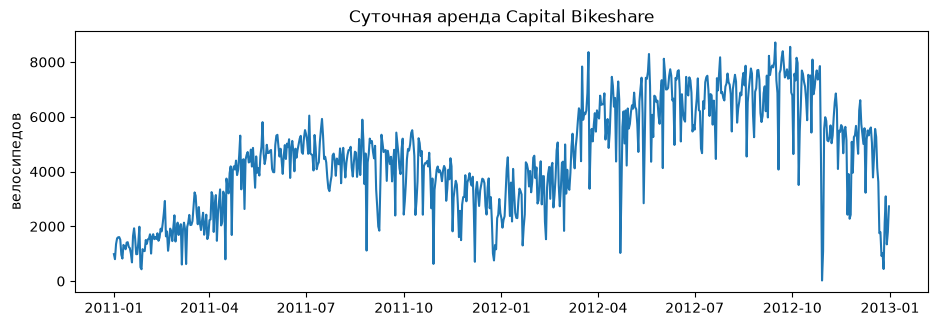

In [89]:
plt.figure(figsize=(11, 3.4))
plt.plot(raw.index, raw['y'])
plt.title('Суточная аренда Capital Bikeshare')
plt.ylabel('велосипедов')
plt.show()

train 584 2011-01-01 2012-08-06
test  147 2012-08-07 2012-12-31


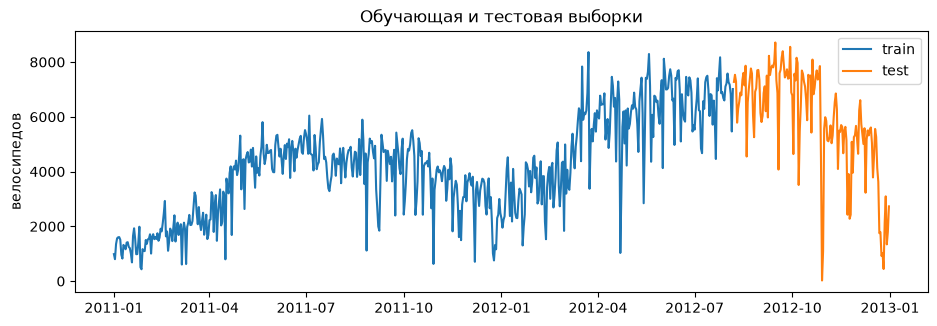

In [90]:
split = int(len(raw) * 0.8)
train = raw.iloc[:split].copy()
test = raw.iloc[split:].copy()
print('train', len(train), train.index.min().date(), train.index.max().date())
print('test ', len(test), test.index.min().date(), test.index.max().date())

plt.figure(figsize=(11, 3.4))
plt.plot(train.index, train['y'], label='train')
plt.plot(test.index, test['y'], label='test')
plt.ylabel('велосипедов')
plt.title('Обучающая и тестовая выборки')
plt.legend()
plt.show()

__Описание__: \
Разрез 80/20 по времени. Train (584 дня) с 1 января 2011 по 6 августа 2012. Test (147 дней) с 7 августа по 31 декабря 2012.

In [91]:
adf_test(train['y'])
print('---')
kpss_test(train['y'])

Results of Dickey-Fuller Test:
Test Statistic                  -1.542329
p-value                          0.512478
#Lags Used                      10.000000
Number of Observations Used    573.000000
Critical Value (1%)             -3.441814
Critical Value (5%)             -2.866597
Critical Value (10%)            -2.569463
dtype: float64
---
Results of KPSS Test:
Test Statistic            2.100955
p-value                   0.010000
Lags Used                15.000000
Critical Value (10%)      0.347000
Critical Value (5%)       0.463000
Critical Value (2.5%)     0.574000
Critical Value (1%)       0.739000
dtype: float64


C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\106976564.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag="AIC")
C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\11026176.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpsstest = kpss(timeseries, regression="c", nlags="auto")
C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\11026176.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea

__Комментарий:__ \
**ADF:** статистика −1.54, p = 0.51, лагов 10, наблюдений 573. Пороги −3.44, −2.87 и −2.57. \
Статистика не доходит даже до 10%, p больше 0.05. Единичный корень не отвергается, по этому тесту ряд нестационарен. \
**KPSS:** статистика 2.10, p = 0.01, лагов 15. Пороги 0.35, 0.46, 0.57 и 0.74. \
Статистика выше всех, p меньше 0.05. Гипотеза стационарности отвергается. \
Ряд **нестационарен**.

In [92]:
adf_test(train['y'].diff().dropna())
print('---')
kpss_test(train['y'].diff().dropna())

Results of Dickey-Fuller Test:
Test Statistic                -1.054170e+01
p-value                        8.616831e-19
#Lags Used                     1.200000e+01
Number of Observations Used    5.700000e+02
Critical Value (1%)           -3.441875e+00
Critical Value (5%)           -2.866624e+00
Critical Value (10%)          -2.569478e+00
dtype: float64
---
Results of KPSS Test:
Test Statistic             0.110632
p-value                    0.100000
Lags Used                146.000000
Critical Value (10%)       0.347000
Critical Value (5%)        0.463000
Critical Value (2.5%)      0.574000
Critical Value (1%)        0.739000
dtype: float64


C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\106976564.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag="AIC")
C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\11026176.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpsstest = kpss(timeseries, regression="c", nlags="auto")
C:\Users\n.osipov\AppData\Local\Temp\ipykernel_19248\11026176.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In relea

__Комментарий:__ \
**ADF:** статистика −10.54, p ≈ 0, лагов 12, наблюдений 570. Статистика далеко за порогом −3.44, p меньше 0.05. Единичный корень отвергается, по ADF разность стационарна. \
**KPSS:** статистика 0.11, p = 0.1, лагов 146. Пороги те же, 0.35 и выше. Статистика ниже самого мягкого порога, p больше 0.05. Стационарность не отвергается. \
На разности оба теста тоже сходятся, уже в другую сторону, поэтому **разность стационарна**.

корреляция, train: 0.685
праздник: 3576.0
обычный день: 4169.9


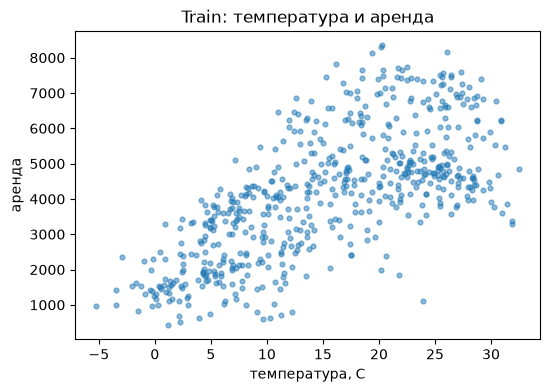

In [93]:
print('корреляция, train:', train['temp_c'].corr(train['y']).round(3))
print('праздник:', train.loc[train.holiday == 1, 'y'].mean().round(1))
print('обычный день:', train.loc[train.holiday == 0, 'y'].mean().round(1))

plt.figure(figsize=(6, 4))
plt.scatter(train['temp_c'], train['y'], s=12, alpha=0.5)
plt.xlabel('температура, C')
plt.ylabel('аренда')
plt.title('Train: температура и аренда')
plt.show()

__Комментарий:__ \
На train корреляция температуры и аренды 0.685. Связь прямая и довольно сильная. Чем теплее день => тем больше берут велосипедов. \
По празднику разница тоже есть, но меньше. В праздник средняя аренда 3576, в обычный день 4169.9, то есть примерно на 600 велосипедов ниже. \
На диаграмме то же, что в корреляции. Ниже 5 °C точки в основном у 1000–3000, выше 20 °C они уходят к 5000–8000. Облако широкое. При одной и той же температуре день может дать и 3000, и 7000. Несколько низких точек есть и при тёплой погоде, температура объясняет не всё.

In [94]:
exog_cols = ['holiday', 'temp_c']
sarimax = SARIMAX(
    train['y'], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
    exog=train[exog_cols],
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
print(sarimax.summary())

                                     SARIMAX Results                                     
Dep. Variable:                                 y   No. Observations:                  584
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood               -4661.167
Date:                           Fri, 09 Oct 2026   AIC                           9336.333
Time:                                   15:49:44   BIC                           9366.802
Sample:                               01-01-2011   HQIC                          9348.218
                                    - 08-06-2012                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
holiday      -11.7892    210.876     -0.056      0.955    -425.098     401.519
temp_c        86.2744     11.185      7.713

C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


__Комментарий:__ \
Модель SARIMAX(1, 1, 1)×(1, 0, 1, 7) обучена на 584 днях, с 1 января 2011 по 6 августа 2012. AIC 9336.3, BIC 9366.8. \
Температура значима, поскольку коэффициент 86.3, ошибка 11.2, p = 0. На один градус модель закладывает около 86 велосипедов. Праздник не значим, так как коэффициент −11.8 при ошибке 211, p = 0.955. Интервал от −425 до 402, ноль внутри. \
ar.L1 = 0.31 и ma.L1 = −0.92, оба p = 0. Сезонные коэффициенты на лаге 7 незначимы, его ar.S.L7 = −0.12, p = 0.924, ma.S.L7 = 0.09, p = 0.944. Ошибки у них больше самих коэффициентов. \
По первому лагу остатков Ljung-Box даёт Q = 0.03 и p = 0.86, автокорреляции на лаге 1 нет. Jarque-Bera 434, p = 0: остатки не нормальны, скос −1.04, эксцесс 6.71. Тест на гетероскедастичность тоже не проходит, H = 2.94, p = 0: разброс остатков по ряду не одинаковый. sigma2 около 661 000, это разброс порядка 800 велосипедов. 

In [97]:
sarima = SARIMAX(
    train['y'], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)

      lb_stat  lb_pvalue
7   11.176193   0.010810
14  13.972166   0.174265
28  31.434159   0.141655


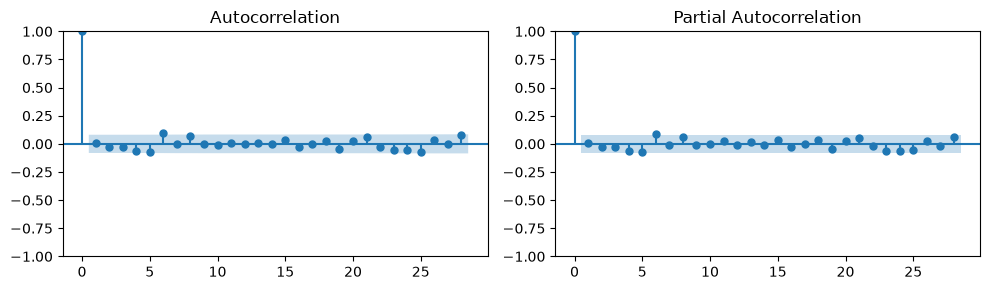

In [98]:
resid = sarimax.resid.dropna()
print(acorr_ljungbox(resid, lags=[7, 14, 28], model_df=4, return_df=True))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(resid, lags=28, ax=ax[0])
plot_pacf(resid, lags=28, ax=ax[1])
plt.tight_layout()
plt.show()

__Комментарий:__ \
Ljung-Box на остатках посчитан на лагах 7, 14 и 28, с поправкой на 4 оценённых коэффициента. \
На лаге 7 статистика 11.18, p = 0.011. Это меньше 0.05, гипотеза «автокорреляции нет» отвергается. На 14 лагах статистика 13.97, p = 0.174. На 28 лагах 31.43, p = 0.142. Оба больше 0.05, на этих горизонтах отвергнуть нулевую гипотезу уже нельзя. \
На графиках лаг 0 равен 1, его не читают. Почти все остальные столбики внутри полосы. На ACF чуть выходит лаг 7, на PACF тоже есть небольшой столбик около 7. Это тот же сигнал, что и p = 0.011: на недельном лаге в остатках ещё есть связь, дальше по лагам её уже не видно.

In [99]:
def to_sf(data):
    out = data.reset_index().rename(columns={'ds': 'ds'})
    out['unique_id'] = 'bikes'
    return out

train_sf = to_sf(train)[['unique_id', 'ds', 'y']]
test_sf = to_sf(test)[['unique_id', 'ds', 'y']]
train_x = to_sf(train)[['unique_id', 'ds', 'y', 'holiday', 'temp_c']]
test_x = to_sf(test)[['unique_id', 'ds', 'holiday', 'temp_c']]

arima_options = dict(season_length=7, max_p=2, max_q=2, max_P=1, max_Q=1)
sf_sarima = StatsForecast(models=[AutoARIMA(**arima_options)], freq='D')
fc_sarima = sf_sarima.forecast(df=train_sf, h=len(test))
sf_sarimax = StatsForecast(models=[AutoARIMA(**arima_options)], freq='D')
fc_sarimax = sf_sarimax.forecast(df=train_x, h=len(test), X_df=test_x)
print(forecast_errors(test['y'], fc_sarima['AutoARIMA']))
print(forecast_errors(test['y'], fc_sarimax['AutoARIMA']))

{'MAE': np.float64(1998.8976070897108), 'RMSE': np.float64(2803.860205684486), 'WAPE(%)': np.float64(33.89224261337815), 'MAPE(%)': np.float64(312.48636099397737)}
{'MAE': np.float64(1222.5994456380936), 'RMSE': np.float64(1701.8125118600349), 'WAPE(%)': np.float64(20.729744677055994), 'MAPE(%)': np.float64(235.12096299824222)}


__Комментарий:__ \
AutoARIMA посчитан дважды на тех же 147 днях test, сезон 7, порядки не выше 2. \
Без колонок MAE 1999, RMSE 2804, WAPE 33.9%. С праздником и температурой MAE 1223, RMSE 1702, WAPE 20.7%. Колонки срезают ошибку примерно на 775 велосипедов. \
MAPE в обоих случаях выше 200%, 312% и 235%. На этом ряде он раздувается из-за дня с почти нулевой арендой, по нему модели не сравниваю. По MAE и WAPE вариант с колонками лучше.

In [100]:
val_h = 60
y_tr, y_val = train.iloc[:-val_h], train.iloc[-val_h:]
param_grid = {
    'changepoint_prior_scale': [0.05, 0.2],
    'seasonality_prior_scale': [1.0, 10.0],
}
all_params = [dict(zip(param_grid, values)) for values in itertools.product(*param_grid.values())]
tuning_rows = []
for params in all_params:
    model = fp.Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False, **params)
    model.add_regressor('holiday')
    model.add_regressor('temp_c')
    frame = y_tr.reset_index()
    model.fit(frame[['ds', 'y', 'holiday', 'temp_c']])
    fut = y_val.reset_index()
    pred = model.predict(fut[['ds', 'holiday', 'temp_c']])['yhat'].to_numpy()
    tuning_rows.append({**params, 'MAE': np.abs(y_val['y'].to_numpy() - pred).mean()})
tuning_results = pd.DataFrame(tuning_rows).sort_values('MAE')
tuning_results

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:50:19 - cmdstanpy - INFO - Chain [1] start processing
15:50:19 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:50:19 - cmdstanpy - INFO - Chain [1] start processing
15:50:20 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent o

,changepoint_prior_scale,seasonality_prior_scale,MAE
1,0.05,10.0,897.290886
0,0.05,1.0,897.327137
2,0.20,1.0,901.428240
3,0.20,10.0,901.545377


__Комментарий:__ \
Сетка Prophet прогнана на последних 60 днях train. Четыре пары: changepoint_prior_scale 0.05 и 0.2, seasonality_prior_scale 1 и 10. В каждую пару добавлены праздник и температура. \
Минимальная MAE у пары 0.05 и 10: 897.3. Соседняя, 0.05 и 1, даёт 897.3, разница меньше велосипеда. Обе пары с 0.2 хуже: 901.4 и 901.5. По этой проверке тренд лучше держать гладким, а сила сезонности почти ничего не меняет.

In [79]:
best_params = tuning_results.iloc[0][list(param_grid)].to_dict()
best_params

{'changepoint_prior_scale': 0.05, 'seasonality_prior_scale': 10.0}

__Комментарий:__ \
Из сетки взята первая строка, у неё была минимальная MAE. В best_params попали changepoint_prior_scale 0.05 и seasonality_prior_scale 10. Дальше Prophet учится уже с этими двумя числами.

In [101]:
def fit_prophet(data, use_x):
    model = fp.Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False, **best_params)
    frame = data.reset_index()
    cols = ['ds', 'y']
    if use_x:
        model.add_regressor('holiday')
        model.add_regressor('temp_c')
        cols += ['holiday', 'temp_c']
    model.fit(frame[cols])
    return model

prophet_x = fit_prophet(train, True)
prophet_0 = fit_prophet(train, False)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:51:28 - cmdstanpy - INFO - Chain [1] start processing
15:51:28 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:51:28 - cmdstanpy - INFO - Chain [1] start processing
15:51:28 - cmdstanpy - INFO - Chain [1] done processing


__Комментарий:__ \
На всём train обучены два Prophet с уже выбранными параметрами, 0.05 и 10. У обоих включены неделя и год, дневной сезон выключен. \
prophet_x получает праздник и температуру. prophet_0 учится только на ряде, без колонок.

In [102]:
models = [
    MSTL(season_length=[7, 365], trend_forecaster=AutoARIMA(max_p=2, max_q=2, seasonal=False)),
    AutoTheta(season_length=7),
    HoltWinters(season_length=7, error_type='A'),
    SeasonalNaive(season_length=7),
]
sf_pipeline = StatsForecast(models=models, freq='D')
pipeline_test = sf_pipeline.forecast(df=train_sf, h=len(test))
pipeline_test.head()

,unique_id,ds,MSTL,AutoTheta,HoltWinters,SeasonalNaive
0,bikes,2012-08-07,6982.387207,7053.553223,6957.890625,7216.0
1,bikes,2012-08-08,7121.181641,6769.857422,6816.915039,7580.0
2,bikes,2012-08-09,7378.288086,7067.111816,7009.522461,7261.0
3,bikes,2012-08-10,7229.186523,7199.480957,7026.137207,7175.0
4,bikes,2012-08-11,6877.496582,6836.006836,6940.859375,6824.0


__Комментарий:__ \
Четыре модели из statsforecast обучены на train и выдают прогноз на весь test, с 7 августа 2012. Сезон у всех 7, у MSTL ещё и 365. Регрессоры сюда не передавались. \
На первые пять дней test прогнозы лежат рядом, около 6800–7400. Сезонный наивный просто повторяет прошлую неделю: 7216, 7580, 7261, 7175, 6824. MSTL, AutoTheta и Holt–Winters в эти дни дают 6800–7400, без такого же скачка на второй день. Ошибку по этим пяти строкам не считают, это только начало прогноза.

In [60]:
crossvalidation_df = sf_pipeline.cross_validation(
    df=train_sf, h=30, step_size=30, n_windows=3,
)
model_names = [c for c in crossvalidation_df.columns if c not in ('unique_id', 'ds', 'cutoff', 'y')]
evaluate(crossvalidation_df, metrics=[mae, rmse], models=model_names)

,unique_id,cutoff,metric,MSTL,AutoTheta,HoltWinters,SeasonalNaive
0,bikes,2012-05-08,mae,981.050903,1072.749390,1007.379089,931.200012
1,bikes,2012-06-07,mae,956.660156,816.619507,833.542603,1195.866699
2,bikes,2012-07-07,mae,1136.949707,805.501343,798.046509,843.566650
3,bikes,2012-05-08,rmse,1271.774902,1289.508423,1231.805664,1161.586792
4,bikes,2012-06-07,rmse,1188.717041,1053.027222,1081.952515,1561.032227
5,bikes,2012-07-07,rmse,1332.779785,929.899475,923.776001,1018.626526


__Комментарий:__ \
Кросс-валидация на train: три окна по 30 дней, шаг 30. Точки отсечения 8 мая, 7 июня и 7 июля 2012. Считались MAE и RMSE. \
На первом окне лучший сезонный наивный, MAE 931. MSTL 981, Holt–Winters 1007, AutoTheta 1073. На втором AutoTheta 817 и Holt–Winters 834, MSTL 957, наивный уже 1196. На третьем снова Holt–Winters 798 и AutoTheta 806, наивный 844, MSTL 1137. \
По RMSE порядок тот же. На этих трёх окнах Holt–Winters и AutoTheta стабильнее: наивный один раз первый и один раз последний, MSTL нигде не первый.

In [61]:
h = 30
origins = [int(len(train) * p) for p in (0.7, 0.8, 0.9)]
cv_rows = []
for origin in origins:
    tr = train.iloc[:origin]
    va = train.iloc[origin:origin + h]
    sx = SARIMAX(tr['y'], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), exog=tr[exog_cols], enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    s0 = SARIMAX(tr['y'], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    cv_rows.append({'Модель': 'SARIMAX', **forecast_errors(va['y'], sx.get_forecast(h, exog=va[exog_cols]).predicted_mean)})
    cv_rows.append({'Модель': 'SARIMA', **forecast_errors(va['y'], s0.get_forecast(h).predicted_mean)})
    px = fit_prophet(tr, True)
    p0 = fit_prophet(tr, False)
    fut = va.reset_index()
    cv_rows.append({'Модель': 'Prophet с колонками', **forecast_errors(va['y'], px.predict(fut[['ds', 'holiday', 'temp_c']])['yhat'])})
    cv_rows.append({'Модель': 'Prophet', **forecast_errors(va['y'], p0.predict(fut[['ds']])['yhat'])})
cv = pd.DataFrame(cv_rows)
cv.groupby('Модель')[['MAE', 'RMSE', 'WAPE(%)']].mean().sort_values('MAE').round(1)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:22:34 - cmdstanpy - INFO - Chain [1] start processing
12:22:34 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:22:35 - cmdstanpy - INFO - Chain [1] start processing
12:22:35 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Chec

,MAE,RMSE,WAPE(%)
Модель,,,
SARIMAX,903.1,1178.0,16.9
SARIMA,927.2,1192.0,18.2
Prophet с колонками,979.0,1220.9,18.0
Prophet,1008.8,1279.1,18.7


__Комментарий:__ \
Три окна по 30 дней на 70, 80 и 90 процентах train. На каждом окне учатся четыре модели, в таблицу попало среднее. \
SARIMAX: MAE 903.1, RMSE 1178, WAPE 16.9%. SARIMA без колонок: 927.2, 1192, 18.2%. Prophet с колонками: 979.0, 1220.9, 18.0%. Prophet без колонок: 1008.8, 1279.1, 18.7%. \
По всем трём метрикам порядок один. Колонки снижают MAE и у SARIMAX, и у Prophet: на 24 и на 30 велосипедов. На этих окнах меньшая средняя ошибка у SARIMAX.

In [62]:
fc_sx = sarimax.get_forecast(len(test), exog=test[exog_cols]).predicted_mean
fc_s = sarima.get_forecast(len(test)).predicted_mean
fut = test.reset_index()
fc_px = prophet_x.predict(fut[['ds', 'holiday', 'temp_c']])['yhat']
fc_p0 = prophet_0.predict(fut[['ds']])['yhat']

rows = [
    {'Модель': 'SARIMAX', **forecast_errors(test['y'], fc_sx)},
    {'Модель': 'SARIMA', **forecast_errors(test['y'], fc_s)},
    {'Модель': 'Prophet с колонками', **forecast_errors(test['y'], fc_px)},
    {'Модель': 'Prophet', **forecast_errors(test['y'], fc_p0)},
]
for col in pipeline_test.columns:
    if col in ('unique_id', 'ds'):
        continue
    rows.append({'Модель': col, **forecast_errors(test['y'], pipeline_test[col])})
pd.DataFrame(rows).set_index('Модель').sort_values('MAE').round(1)

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet с колонками,1055.7,1412.8,17.9,219.8
Prophet,1087.4,1494.2,18.4,219.9
MSTL,1147.6,1525.6,19.5,204.4
SARIMAX,1170.3,1519.5,19.8,208.3
SeasonalNaive,1506.1,2136.8,25.5,272.6
SARIMA,1515.6,2092.5,25.7,266.3
AutoTheta,1827.1,2571.8,31.0,294.0
HoltWinters,1925.6,2707.4,32.6,303.5


__Комментарий:__ \
На отложенных 147 днях, с 7 августа по 31 декабря 2012, модели уже не выбирались, только считалась ошибка. \
По MAE первый Prophet с колонками, 1055.7. Дальше Prophet без колонок 1087.4, MSTL 1147.6, SARIMAX 1170.3. Сезонный наивный 1506.1, SARIMA 1515.6. AutoTheta 1827.1 и Holt–Winters 1925.6 замыкают таблицу. По RMSE и WAPE порядок тот же. \
Колонки и здесь снижают ошибку. У Prophet разница 32 велосипеда, у SARIMAX против SARIMA уже 345. MAPE у всех выше 200%, от 204% у MSTL до 304% у Holt–Winters. На этом куске он раздут днём с почти нулевой арендой, по нему модели не расходятся с MAE только у хвоста таблицы.

In [63]:
print('AutoARIMA без колонок', forecast_errors(test['y'], fc_sarima['AutoARIMA']))
print('AutoARIMA с колонками', forecast_errors(test['y'], fc_sarimax['AutoARIMA']))

sf_mae = evaluate(
    crossvalidation_df, metrics=[mae], models=['MSTL', 'AutoTheta', 'HoltWinters', 'SeasonalNaive']
)
print(sf_mae)
print(sf_mae[['MSTL', 'AutoTheta', 'HoltWinters', 'SeasonalNaive']].mean())

AutoARIMA без колонок {'MAE': np.float64(1998.8976070897108), 'RMSE': np.float64(2803.860205684486), 'WAPE(%)': np.float64(33.89224261337815), 'MAPE(%)': np.float64(312.48636099397737)}
AutoARIMA с колонками {'MAE': np.float64(1222.5994456380936), 'RMSE': np.float64(1701.8125118600349), 'WAPE(%)': np.float64(20.729744677055994), 'MAPE(%)': np.float64(235.12096299824222)}
  unique_id     cutoff metric         MSTL    AutoTheta  HoltWinters  \
0     bikes 2012-05-08    mae   981.050903  1072.749390  1007.379089   
1     bikes 2012-06-07    mae   956.660156   816.619507   833.542603   
2     bikes 2012-07-07    mae  1136.949707   805.501343   798.046509   

   SeasonalNaive  
0     931.200012  
1    1195.866699  
2     843.566650  
MSTL             1024.886841
AutoTheta         898.290039
HoltWinters       879.656067
SeasonalNaive     990.211121
dtype: float32


__Комментарий:__ \
AutoARIMA на test: без колонок MAE 1999, RMSE 2804, WAPE 33.9%. С праздником и температурой MAE 1223, RMSE 1702, WAPE 20.7%. Колонки срезают около 775 велосипедов. MAPE снова выше 200%. \
Ниже кросс-валидация MSTL, AutoTheta, Holt–Winters и сезонного наивного. Окна те же, что раньше: 8 мая, 7 июня и 7 июля, горизонт 30. Средний MAE: Holt–Winters 880, AutoTheta 898, сезонный наивный 990, MSTL 1025. На этих датах лучший Holt–Winters. Это не окна 70, 80 и 90 процентов train, где считались SARIMAX и Prophet.

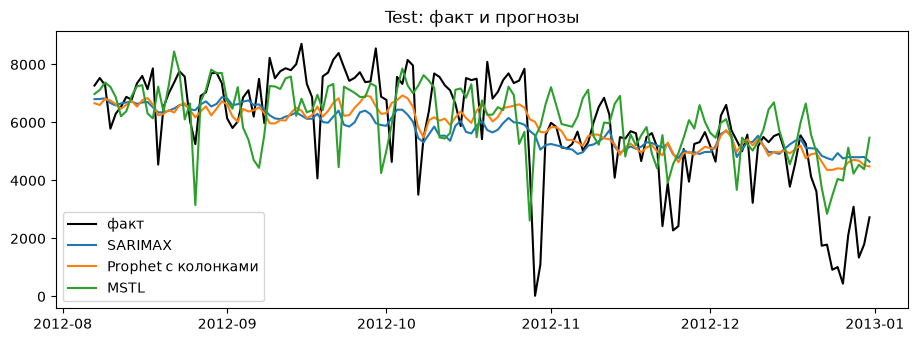

In [64]:
plt.figure(figsize=(11, 3.6))
plt.plot(test.index, test['y'], color='black', label='факт')
plt.plot(test.index, fc_sx, label='SARIMAX')
plt.plot(test.index, fc_px, label='Prophet с колонками')
plt.plot(test.index, pipeline_test['MSTL'], label='MSTL')
plt.legend()
plt.title('Test: факт и прогнозы')
plt.show()

__Комментарий:__ \
На графике факт и три прогноза с 7 августа по 31 декабря 2012. Чёрный ряд скачет: в августе и сентябре он в основном между 6000 и 8000, в конце октября падает почти до нуля, к декабрю спускается к 1000–3000. \
Синий SARIMAX и оранжевый Prophet идут глаже и рядом. До октября они держатся около 6000–7000 и не берут ни недельные скачки, ни обрыв в конце октября. Дальше оба снижаются, но остаются выше факта, особенно в декабре. \
Зелёный MSTL повторяет неделю сильнее: провалы в сентябре и тот же обрыв в конце октября у него глубже, чем у двух других. Декабрьский спад он тоже не добирает и в конце уходит вверх, тогда как факт остаётся низким.

C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


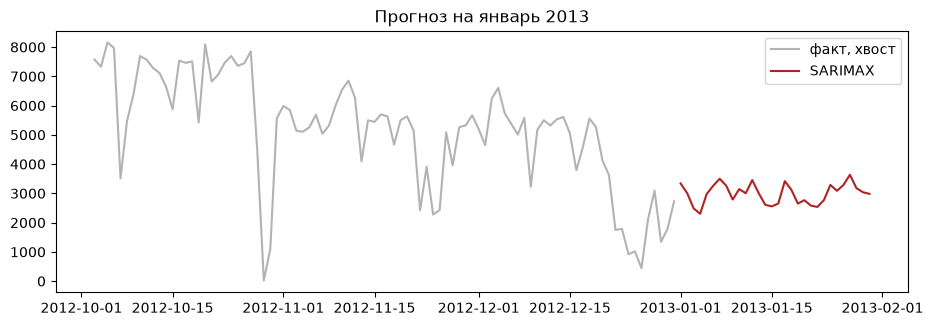

2013-01-01    3339.0
2013-01-02    3010.0
2013-01-03    2487.0
2013-01-04    2303.0
2013-01-05    2975.0
2013-01-06    3259.0
2013-01-07    3498.0
2013-01-08    3264.0
2013-01-09    2788.0
2013-01-10    3146.0
Freq: D, Name: predicted_mean, dtype: float64

In [65]:
future_idx = pd.date_range(raw.index.max() + pd.Timedelta(days=1), periods=30, freq='D')
temp_scenario = []
for day in future_idx:
    same = raw.loc[raw.index.strftime('%m-%d') == day.strftime('%m-%d'), 'temp_c']
    temp_scenario.append(same.iloc[-1])
X_future = pd.DataFrame({
    'holiday': [int(day == pd.Timestamp('2013-01-01')) for day in future_idx],
    'temp_c': temp_scenario,
}, index=future_idx)

full = SARIMAX(
    raw['y'], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
    exog=raw[exog_cols],
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
future = full.get_forecast(30, exog=X_future).predicted_mean

plt.figure(figsize=(11, 3.4))
plt.plot(raw.index[-90:], raw['y'].iloc[-90:], color='0.7', label='факт, хвост')
plt.plot(future.index, future, color='firebrick', label='SARIMAX')
plt.legend()
plt.title('Прогноз на январь 2013')
plt.show()
future.round(0).head(10)

__Комментарий:__ \
SARIMAX переучен на всём ряде, с 1 января 2011 по 31 декабря 2012, и выдаёт 30 дней с 1 января 2013. Праздник стоит только на 1 января. Температура на эти дни взята с тех же чисел 2012 года, фактической температуры января 2013 в ряде нет. \
Прогноз лежит между 2303 и 3498. Первые десять дней: 3339, 3010, 2487, 2303, 2975, 3259, 3498, 3264, 2788, 3146. На графике это красная линия с недельной волной, она стыкуется с серым хвостом 2012 года и не уходит ни к нулю, ни обратно к летним 7000. Это сценарий при прошлогодней температуре, не факт января 2013.